In [1]:
from dataclasses import dataclass
import jax, jax.numpy as jnp, numpy as np
import matplotlib.pyplot as plt
import gebtaero_jax as gx
from gebtaero_jax import section as sec, coupled, aerodynamics as aero

In [2]:
@dataclass(frozen=True)
class NonlinearSection:
    """Typical section with k_θ(θ) = k_θ (1 + κ₃ θ²)."""
    n_states: int = 4
    def residual(self, dx, x, y, p, t):
        dh, dth, dhd, dthd = dx; h, th, hd, thd = x; L, M = y
        s, k3 = p
        return jnp.stack([dh - hd, dth - thd,
                          s.m * dhd + s.Stheta * dthd + s.kh * h + L,
                          s.Stheta * dhd + s.Itheta * dthd + s.ktheta * (1 + k3 * th**2) * th - M])

@dataclass(frozen=True)
class FlapActuator:
    """First-order actuator: τ δ̇ + δ = δ_cmd (commanded by a pitch-rate feedback law)."""
    n_states: int = 1
    def residual(self, dx, x, y, p, t):
        tau = p
        return jnp.atleast_1d(tau * dx[0] + x[0] - y)

peters = sec.Peters(6)
A, bbar, cbar = aero.peters_constants(6)

def coupling(dxs, xs, p, t):
    dlam, dxs_s, ddelta = dxs
    lam, xs_s, delta = xs
    s, k3, tau, gain = p["section"], p["k3"], p["tau"], p["gain"]
    h, th, hd, thd = xs_s
    u, v, om, vd, omd = s.U, s.U * th + hd, thd, dxs_s[2], dxs_s[3]
    v = v + s.U * 0.6 * delta[0]  # flap effectiveness: Δα_eff = 0.6 δ (simple quasi-steady model)
    N, M = aero.peters_loads(s.a, s.b, s.a0, s.alpha0, s.cm0, s.rho, 1.0, bbar, u, v, om, vd, omd, lam)
    delta_cmd = -gain * thd  # pitch-rate damping law
    return (u, om, vd, omd), (N, M), delta_cmd

model = coupled.CoupledModel(
    (peters, NonlinearSection(), FlapActuator()),
    coupling,
    lambda p: (p["section"], (p["section"], p["k3"]), p["tau"]),
)
p_sec = sec.SectionParameters.from_nondimensional(a=-0.2, e=-0.1, mu=20, r2=0.24, sigma=0.4, V=1.0)
params = lambda V, gain=0.0, k3=20.0: {"section": p_sec.replace(U=V), "k3": k3, "tau": 0.1, "gain": gain}
print("states:", model.n_states)

states: 11


## Linear flutter speed, open and closed loop

In [3]:
for gain in [0.0, 0.5, 1.0]:
    Vf, s = coupled.critical_value(model, lambda v: params(v, gain), 0.5, 4.0, 30)
    print(f"feedback gain {gain:3.1f}:  V_f = {Vf:.4f}, ω_f/ω_θ = {s.imag:.4f}")

feedback gain 0.0:  V_f = 2.1654, ω_f/ω_θ = 0.6545
feedback gain 0.5:  V_f = 2.2317, ω_f/ω_θ = 0.5598
feedback gain 1.0:  V_f = 2.1979, ω_f/ω_θ = 0.5138


## Limit-cycle oscillations above the (open-loop) flutter speed
The hardening spring bounds the amplitude; the LCO amplitude grows with the distance from the flutter speed.

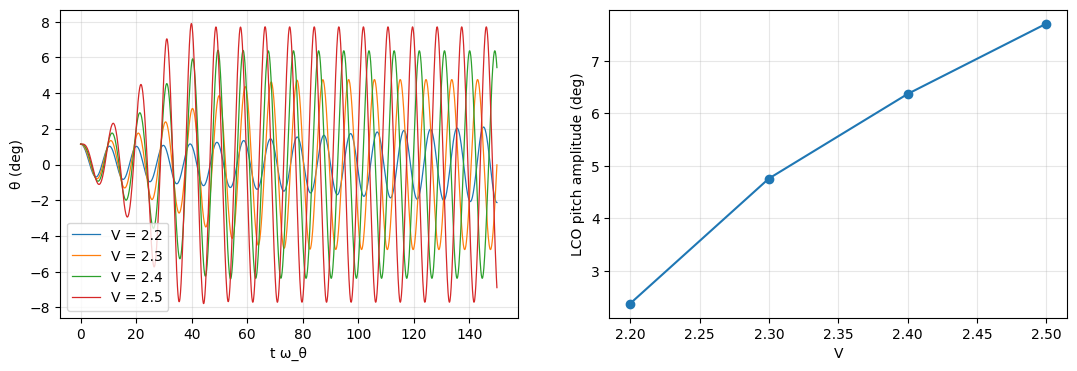

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
amps = []
Vs = [2.2, 2.3, 2.4, 2.5]
for V in Vs:
    x0 = jnp.zeros(model.n_states).at[7].set(0.02)
    t, X = coupled.simulate(model, params(V), x0, t_end=400.0, dt=0.1)
    w = t <= 150
    axs[0].plot(t[w], np.degrees(X[w, 7]), lw=0.9, label=f"V = {V}")
    amps.append(np.degrees(np.abs(X[t > 300, 7]).max()))
axs[0].set_xlabel("t ω_θ"); axs[0].set_ylabel("θ (deg)"); axs[0].legend(); axs[0].grid(alpha=.3)
axs[1].plot(Vs, amps, "o-"); axs[1].set_xlabel("V"); axs[1].set_ylabel("LCO pitch amplitude (deg)"); axs[1].grid(alpha=.3);

## Differentiating through a whole simulation
`coupled.simulate` is a compiled `lax.scan`, so the final energy of a transient can be differentiated w.r.t. the
controller gain — the starting point for gradient-based controller tuning.

In [5]:
def final_pitch_energy(gain):
    x0 = jnp.zeros(model.n_states).at[7].set(0.05)
    fun = lambda xn, xdn, t, prm: model.residual(xdn, xn, prm, t)
    xs = gx.integrators.generalized_alpha(fun, x0, jnp.zeros_like(x0), params(2.3, gain), 0.1, 300)
    return jnp.mean(xs[-50:, 7] ** 2)

for g in [0.0, 0.3, 0.6]:
    val, dval = jax.value_and_grad(final_pitch_energy)(g)
    print(f"gain {g:.1f}: mean θ² over last 5 time units = {float(val):.3e},  d/dgain = {float(dval):.3e}")

gain 0.0: mean θ² over last 5 time units = 2.416e-03,  d/dgain = -1.157e-02


gain 0.3: mean θ² over last 5 time units = 1.018e-03,  d/dgain = -1.007e-03


gain 0.6: mean θ² over last 5 time units = 7.806e-04,  d/dgain = -7.424e-04
